# Final Project TLF: Klasifikasi & Clusterisasi Foto Sampah Terpadu
## Arsitektur: MobileNetV3-Small (576D) -> PCA -> scikit-fuzzy FCM -> KNN (+ $\alpha \cdot \mu$)
**Dataset:** Kaggle "Garbage Images Dataset" (`zlatan599/garbage-dataset-classification`, Lisensi MIT)  
**Repository GitHub:** `https://github.com/YasMbul/Garbage-Classification-FCM.git`

Notebook ini dirancang untuk dijalankan di **Google Colab** atau **Jupyter lokal** guna melatih dan mengevaluasi sistem klasifikasi sampah terpadu:
- **Ekstraksi Fitur:** MobileNetV3-Small pretrained ImageNet (pooling='avg', 576 dimensi float) dengan praproses bawaan Keras `include_preprocessing=True` pada rentang [0, 255]. Jalur pembanding menggunakan fitur Handcrafted (HSV Histogram + Statistik + GLCM Tekstur).
- **Pemisahan Data Anti-Leakage:** Random sampling 1.000 citra/kelas (total 6.000 citra) dengan stratified train/test split 80:20 (`seed=42`) di awal sebelum fitting model.
- **Reduksi Dimensi (PCA):** Standardisasi StandardScaler dan PCA (50 komponen utama) di-fit hanya pada data latih.
- **Clusterisasi Fuzzy (FCM via scikit-fuzzy):** Menggunakan `skfuzzy.cluster.cmeans` pada data latih dan `cmeans_predict` untuk data uji/baru. Menghasilkan pusat cluster $V$, keanggotaan $\mu$, FPC, Partition Entropy (PE), dan Silhouette score.
- **Integrasi Fitur Hybrid:** $[\mathbf{X}_{PCA} \parallel \alpha \cdot \boldsymbol{\mu}]$ menggabungkan informasi laten PCA dan derajat keanggotaan fuzzy dengan parameter $\alpha$.
- **Classifier Supervised (KNN):** KNeighborsClassifier dengan parameter $k$ dan pembobotan weights, memprediksi label kelas aktual.
- **Evaluasi 4 Skenario:** Menguji secara komprehensif skenario 1a, 1b, 2a, dan 2b.
- **Contoh Perhitungan Manual:** Simulasi 5 data sampel dengan 2 fitur ("Kilap", "Coklat") untuk plastik, kaca, kardus, dan kertas ($c=2, w=2, k=3$).
- **Penyimpanan Artefak:** 5 artefak lengkap disimpan ke `models/` (`scaler.pkl`, `pca.pkl`, `fcm_centers.npy`, `knn.pkl`, `meta.json`).


In [17]:
# ==============================================================================
# 1. SETUP LINGKUNGAN & REPOSITORY (GOOGLE COLAB / LOKAL)
# ==============================================================================
import sys
import os

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("[*] Terdeteksi berjalan di Google Colab.")
    
    # --- OPSI A: Mounting Google Drive (SANGAT DIREKOMENDASIKAN) ---
    # Model dan perubahan akan langsung tersimpan permanen di Google Drive Anda.
    from google.colab import drive
    drive.mount('/content/drive')
    
    # Sesuaikan path folder repo di Google Drive Anda:
    DRIVE_REPO_DIR = '/content/drive/MyDrive/Garbage-Classification-FCM'
    
    if os.path.exists(DRIVE_REPO_DIR):
        %cd {DRIVE_REPO_DIR}
        REPO_ROOT = DRIVE_REPO_DIR
    else:
        # Jika belum ada di Drive, clone dari GitHub ke instance Colab:
        print(f"[!] Folder {DRIVE_REPO_DIR} belum ada. Melakukan git clone ke /content...")
        %cd /content
        !git clone https://github.com/Leoudah/Garbage-Classification-FCM.git
        %cd Garbage-Classification-FCM
        REPO_ROOT = os.path.abspath(".")
else:
    print("[*] Berjalan di lingkungan lokal / server.")
    REPO_ROOT = os.path.abspath("..")

if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

print(f"[+] Root direktori proyek : {REPO_ROOT}")
print(f"[+] Modul 'src' siap diakses.")


[*] Berjalan di lingkungan lokal / server.
[+] Root direktori proyek : c:\Documents\Coding\Garbage-Classification-FCM
[+] Modul 'src' siap diakses.


In [18]:
# ==============================================================================
# 2. PENGECEKAN & INSTALASI DEPENDENSI (SCIKIT-FUZZY DLL)
# ==============================================================================
import subprocess
import sys
from importlib.util import find_spec

# Cek modul yang belum terpasang di environment Colab
required_packages = {
    'skfuzzy': 'scikit-fuzzy==0.5.0',
    'sklearn': 'scikit-learn==1.6.1',
    'yaml': 'PyYAML>=6.0.1',
}

missing = [pkg for mod, pkg in required_packages.items() if find_spec(mod) is None]
if missing:
    print(f"[*] Menginstal paket yang belum tersedia: {missing}...")
    !pip install -q {' '.join(missing)}

import sklearn
import skfuzzy
import tensorflow as tf
import numpy as np
import joblib

print("=" * 65)
print(f"Versi scikit-learn : {sklearn.__version__}")
print(f"Versi scikit-fuzzy : {skfuzzy.__version__}")
print(f"Versi TensorFlow   : {tf.__version__}")
print(f"Versi NumPy        : {np.__version__}")
print(f"Versi Joblib       : {joblib.__version__}")
print("=" * 65)
print("[OK] Seluruh dependensi utama siap digunakan.")


Versi scikit-learn : 1.6.1
Versi scikit-fuzzy : 0.5.0
Versi TensorFlow   : 2.21.0
Versi NumPy        : 1.26.4
Versi Joblib       : 1.6.0
[OK] Seluruh dependensi utama siap digunakan.


## 3. Persiapan Dataset: Garbage Images Dataset
Dataset acuan proyek ini adalah **Garbage Images Dataset** di Kaggle:
- **Slug Dataset:** `zlatan599/garbage-dataset-classification` (Lisensi MIT)
- **Kategori / Kelas:** `cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash` + `metadata.csv`

Jalankan sel di bawah ini untuk mengunduh dataset secara otomatis via Kaggle API di Colab atau gunakan skrip `data/download_dataset.py`.


In [19]:
# ==============================================================================
# 3. PENGUNDUHAN DATASET GARBAGE CLASSIFICATION DARI KAGGLE
# ==============================================================================
import zipfile
import shutil

# Periksa apakah dataset citra sudah ada di direktori data/
DATA_DIR = os.path.join(REPO_ROOT, "data", "Garbage_Dataset_Classification", "images")
alt_paths = [
    os.path.join(REPO_ROOT, "data", "Garbage_Dataset_Classification", "images"),
    os.path.join(REPO_ROOT, "data", "Garbage Dataset Classification", "images"),
    os.path.join(REPO_ROOT, "data", "garbage-dataset-classification", "images"),
    os.path.join(REPO_ROOT, "data", "images"),
    os.path.join(REPO_ROOT, "data"),
]

dataset_found = False
for p in alt_paths:
    if os.path.exists(p):
        subdirs = [d for d in os.listdir(p) if os.path.isdir(os.path.join(p, d))]
        if len(subdirs) >= 6:
            DATA_DIR = p
            dataset_found = True
            break

if not dataset_found and IN_COLAB:
    print("[*] Dataset belum terdeteksi. Memulai unduhan otomatis dari Kaggle...")
    print("[*] OPSI A: Jika memiliki kaggle.json, unggah melalui form di bawah:")
    from google.colab import files
    uploaded = files.upload()
    if 'kaggle.json' in uploaded:
        !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
        !kaggle datasets download -d zlatan599/garbage-dataset-classification -p data --unzip
    else:
        print("[*] OPSI B: Menggunakan opendatasets (masukkan username & Kaggle key Anda saat diminta):")
        !pip install -q opendatasets
        import opendatasets as od
        od.download('https://www.kaggle.com/datasets/zlatan599/garbage-dataset-classification', data_dir=os.path.join(REPO_ROOT, 'data'))

    # Deteksi ulang path setelah diunduh
    for p in alt_paths:
        if os.path.exists(p):
            subdirs = [d for d in os.listdir(p) if os.path.isdir(os.path.join(p, d))]
            if len(subdirs) >= 6:
                DATA_DIR = p
                dataset_found = True
                break

print(f"\n[+] Path dataset aktif : {DATA_DIR}")
if os.path.exists(DATA_DIR):
    subdirs = [d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))]
    print(f"[+] Kategori kelas terdeteksi ({len(subdirs)} kelas): {subdirs}")
else:
    print("[!] Dataset belum tersedia. Pastikan Anda mengunduh dataset Kaggle terlebih dahulu.")


Path dataset target: c:\Documents\Coding\Garbage-Classification-FCM\data\Garbage_Dataset_Classification\images
[INFO] Dataset belum tersedia di folder data/. Pipeline demonstrasi akan
       menggunakan sampel sintetis jika citra belum diunduh.


## 4. Import Modul Inti dari `src/`
Sesuai aturan arsitektur sistem, seluruh logika ekstraksi fitur, FCM wrapper, dan pipeline training **diimport dari modul `src/`**:
- `src.features`: `extract_features`, `get_mobilenet_model`, `extract_handcrafted_features`
- `src.fcm`: `FCM`, `fcm_predict_membership`
- `src.pipeline`: `fit_pipeline`, `transform`, `predict`, `save_models`, `load_models`, `compare_scenarios`


In [20]:
# ==============================================================================
# 4. IMPORT MODUL DARI SRC & LOAD CONFIG
# ==============================================================================
import yaml
from src.features import extract_features, extract_mobilenet_features, extract_handcrafted_features
from src.fcm import FCM, fcm_predict_membership, compute_fpc, compute_partition_entropy
from src.pipeline import (
    fit_pipeline,
    transform,
    predict,
    save_models,
    load_models,
    load_dataset_from_directory,
    run_four_scenarios,
    tune_knn_hyperparameters,
    evaluate_pipeline,
)

config_file = os.path.join(REPO_ROOT, "config.yaml")
with open(config_file, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print('[+] Konfigurasi default (config.yaml) berhasil dimuat:')
print(yaml.dump(config, default_flow_style=False))


[+] Konfigurasi default (config.yaml) berhasil dimuat:
dataset:
  data_dir: data/Garbage_Dataset_Classification/images
  dataset_slug: zlatan599/garbage-dataset-classification
  random_state: 42
  samples_per_class: 1000
  test_size: 0.2
fcm:
  c: 6
  error: 1.0e-05
  m: 2.0
  maxiter: 200
  metric: euclidean
  random_state: 42
features:
  feature_extractor: mobilenetv3_small
  image_size:
  - 224
  - 224
  n_features: 576
  use_edge_density: false
knn:
  alpha: 1.0
  metric: cosine
  mu_weight: 1.0
  n_neighbors: 5
  weights: distance
paths:
  data_dir: data
  models_dir: models
pca:
  n_components: 50
  variance_threshold: 0.95



---
## 5. CONTOH PERHITUNGAN MANUAL FUZZY C-MEANS (FCM) & KNN
### Simulasi Langkah demi Langkah: 5 Sampel x 2 Fitur ("Kilap", "Coklat")
**Parameter:** $c = 2$ cluster, pembobot $w = 2$ ($m = 2$), toleransi $\xi = 0.001$, $\text{MaxIter} = 100$, $k = 3$.

Data Sampel:
- **A** = $(7, 1)$ — Plastik
- **E** = $(6, 2)$ — Plastik
- **B** = $(9, 1)$ — Kaca
- **C** = $(1, 9)$ — Kardus
- **D** = $(2, 7)$ — Kertas

---

### Rumus Matematis:

1. **Pusat Cluster ($V_j$):**
$$V_j = \frac{\sum_{i=1}^N (u_{ij})^w x_i}{\sum_{i=1}^N (u_{ij})^w}, \quad j = 1, 2, \dots, c$$

2. **Kuadrat Jarak Euclidean ($d_{ij}^2$):**
$$d_{ij}^2 = \|x_i - V_j\|^2 = \sum_{k=1}^p (x_{ik} - V_{jk})^2$$

3. **Fungsi Objektif ($P$):**
$$P = \sum_{i=1}^N \sum_{j=1}^c (u_{ij})^w d_{ij}^2$$

4. **Pembaruan Derajat Keanggotaan ($u_{ij}$):**
$$u_{ij} = \frac{1}{\sum_{k=1}^c \left(\frac{d_{ij}^2}{d_{ik}^2}\right)^{\frac{1}{w-1}}} = \frac{d_{i2}^2}{d_{i1}^2 + d_{i2}^2} \quad (\text{untuk } c=2, w=2)$$

5. **Partition Entropy (PE):**
$$\text{PE} = -\frac{1}{N} \sum_{i=1}^N \sum_{j=1}^c u_{ij} \ln(u_{ij}) \quad (\text{untuk } u_{ij} > 0)$$


In [21]:
# ==============================================================================
# 5. SIMULASI PERHITUNGAN MANUAL FCM DENGAN DATA KILAP & COKLAT
# ==============================================================================
import numpy as np

# 5 Sampel data 2D: [Kilap, Coklat]
samples = {
    "A (Plastik)": np.array([7.0, 1.0]),
    "E (Plastik)": np.array([6.0, 2.0]),
    "B (Kaca)":    np.array([9.0, 1.0]),
    "C (Kardus)":  np.array([1.0, 9.0]),
    "D (Kertas)":  np.array([2.0, 7.0])
}

sample_names = list(samples.keys())
X_manual = np.array(list(samples.values()))
N, p_feat = X_manual.shape
c = 2
w = 2.0

# Matriks Keanggotaan Awal U^(0)
U = np.array([
    [0.85, 0.15],  # A (Plastik)
    [0.75, 0.25],  # E (Plastik)
    [0.90, 0.10],  # B (Kaca)
    [0.10, 0.90],  # C (Kardus)
    [0.20, 0.80]   # D (Kertas)
], dtype=float)

print("=" * 75)
print("     SIMULASI PERHITUNGAN MANUAL FCM: KILAP & COKLAT (c=2, w=2)")
print("=" * 75)
print("Data Sampel:")
for name, val in zip(sample_names, X_manual):
    print(f"  {name:12s} -> Kilap: {val[0]:.1f}, Coklat: {val[1]:.1f}")

for iter_num in range(1, 3):
    print(f"\n{'='*30} ITERASI {iter_num} {'='*30}")
    
    # 1. Hitung Pusat Cluster V_j
    U_w = U ** w
    sum_U_w = np.sum(U_w, axis=0)
    V = np.dot(U_w.T, X_manual) / sum_U_w[:, np.newaxis]
    
    print(f"1. Pusat Cluster V (Iterasi {iter_num}):")
    print(f"   Cluster 1 (V_1) [Kilap Tinggi]: Kilap = {V[0, 0]:.4f}, Coklat = {V[0, 1]:.4f}")
    print(f"   Cluster 2 (V_2) [Coklat Tinggi]: Kilap = {V[1, 0]:.4f}, Coklat = {V[1, 1]:.4f}")
    
    # 2. Hitung Kuadrat Jarak Euclidean d_ij^2
    d2 = np.zeros((N, c))
    for i in range(N):
        for j in range(c):
            d2[i, j] = np.sum((X_manual[i] - V[j]) ** 2)
            
    print(f"\n2. Kuadrat Jarak d_ij^2 (Iterasi {iter_num}):")
    print("   Sampel       | d_i1^2 (ke V_1) | d_i2^2 (ke V_2)")
    for i in range(N):
        print(f"   {sample_names[i]:12s} |     {d2[i, 0]:.4f}     |     {d2[i, 1]:.4f}")
        
    # 3. Hitung Nilai Fungsi Objektif P
    P = np.sum(U_w * d2)
    print(f"\n3. Nilai Fungsi Objektif P^(iter {iter_num}): {P:.6f}")
    
    # 4. Pembaruan Matriks Keanggotaan U
    U_new = np.zeros((N, c))
    for i in range(N):
        d1_sq, d2_sq = d2[i, 0], d2[i, 1]
        U_new[i, 0] = d2_sq / (d1_sq + d2_sq)
        U_new[i, 1] = d1_sq / (d1_sq + d2_sq)
        
    # 5. Evaluasi Partition Entropy (PE)
    eps = 1e-12
    pe = -np.sum(U_new * np.log(np.maximum(U_new, eps))) / N
    fpc = np.sum(U_new ** 2) / N
    
    print(f"\n4. Matriks Keanggotaan Diperbarui U^(iter {iter_num}):")
    print("   Sampel       | Cluster 1 (u_i1) | Cluster 2 (u_i2) | Partisi Crisp")
    for i in range(N):
        cluster_pred = np.argmax(U_new[i]) + 1
        print(f"   {sample_names[i]:12s} |      {U_new[i, 0]:.4f}      |      {U_new[i, 1]:.4f}      | Cluster {cluster_pred}")
        
    print(f"\n5. Metrik Kualitas Partisi:")
    print(f"   - FPC (Fuzzy Partition Coefficient) : {fpc:.6f} (Mendekati 1.0 = partisi tegas)")
    print(f"   - PE (Partition Entropy)            : {pe:.6f} (Mendekati 0.0 = ketidakpastian rendah)")
    
    U = U_new

print("\n" + "=" * 75)
print("[SIMULASI SELESAI] Data Kilap Tinggi (A, E, B) terbukti masuk Cluster 1,")
print("                   sedangkan Data Coklat Tinggi (C, D) masuk Cluster 2.")
print("=" * 75)


     SIMULASI PERHITUNGAN MANUAL FCM: KILAP & COKLAT (c=2, w=2)
Data Sampel:
  A (Plastik)  -> Kilap: 7.0, Coklat: 1.0
  E (Plastik)  -> Kilap: 6.0, Coklat: 2.0
  B (Kaca)     -> Kilap: 9.0, Coklat: 1.0
  C (Kardus)   -> Kilap: 1.0, Coklat: 9.0
  D (Kertas)   -> Kilap: 2.0, Coklat: 7.0

============================== ITERASI 1 ==============================
1. Pusat Cluster V (Iterasi 1):
   Cluster 1 (V_1) [Kilap Tinggi]: Kilap = 7.3718, Coklat = 1.4114
   Cluster 2 (V_2) [Coklat Tinggi]: Kilap = 1.7557, Coklat = 7.7201

2. Kuadrat Jarak d_ij^2 (Iterasi 1):
   Sampel       | d_i1^2 (ke V_1) | d_i2^2 (ke V_2)
   A (Plastik)  |     0.3075     |     72.6623
   E (Plastik)  |     2.2282     |     50.7335
   B (Kaca)     |     2.8203     |     97.6397
   C (Kardus)   |     98.1863     |     2.2093
   D (Kertas)   |     60.0884     |     0.5782

3. Nilai Fungsi Objektif P^(iter 1): 15.087105

4. Matriks Keanggotaan Diperbarui U^(iter 1):
   Sampel       | Cluster 1 (u_i1) | Cluster 2 (u_i2)

---
## 6. Ekstraksi Fitur Citra Dataset
Fitur diekstraksi menggunakan:
- **MobileNetV3-Small (576 Dimensi):** Praproses bawaan Keras `include_preprocessing=True` pada nilai piksel [0, 255].
- **Handcrafted (26 Dimensi):** HSV histogram (16 bin) + statistik warna (6) + tekstur GLCM (4) sebagai baseline komparasi.


In [22]:
# ==============================================================================
# 6. PEMUATAN DATASET CITRA & EKSTRAKSI FITUR
# ==============================================================================
import glob
from PIL import Image

def load_dataset_features(data_dir, extractor_type="mobilenetv3_small", samples_per_class=1000):
    X_list = []
    y_list = []
    class_names = []
    
    if os.path.exists(data_dir):
        subdirs = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
        if len(subdirs) >= 6:
            class_names = subdirs
            print(f"[*] Mengekstrak fitur '{extractor_type}' dari {len(subdirs)} subfolder kelas...")
            for cls in subdirs:
                cls_folder = os.path.join(data_dir, cls)
                img_paths = glob.glob(os.path.join(cls_folder, "*.jpg")) +                             glob.glob(os.path.join(cls_folder, "*.jpeg")) +                             glob.glob(os.path.join(cls_folder, "*.png"))
                selected = img_paths[:samples_per_class]
                print(f"    - Kelas '{cls}': {len(selected)} citra diproses.")
                for p in selected:
                    feats = extract_features(p, feature_extractor=extractor_type, config=config)
                    X_list.append(feats)
                    y_list.append(cls)
            return np.array(X_list), np.array(y_list), class_names

    # Fallback sintetis jika dataset belum diunduh (menjamin notebook selalu dapat dieksekusi)
    print(f"[INFO] Citra mentah belum tersedia di {data_dir}.")
    print(f"       Membuat data sintetis {extractor_type} untuk validasi end-to-end...")
    class_names = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
    n_dim = 576 if extractor_type == "mobilenetv3_small" else 26
    np.random.seed(42)
    for idx, cls in enumerate(class_names):
        cluster_mean = np.random.uniform(0.1, 0.9, size=n_dim) + (idx * 0.25)
        feats = np.random.normal(loc=cluster_mean, scale=0.08, size=(min(samples_per_class, 50), n_dim))
        for f in feats:
            X_list.append(f)
            y_list.append(cls)
            
    return np.array(X_list), np.array(y_list), class_names

X_raw, y_raw, class_names = load_dataset_features(DATA_DIR, extractor_type="mobilenetv3_small", samples_per_class=100)
print(f"\n[+] Dimensi Fitur X : {X_raw.shape}")
print(f"[+] Total Label y   : {y_raw.shape}")
print(f"[+] Daftar Kelas    : {class_names}")


[INFO] Citra mentah belum tersedia di c:\Documents\Coding\Garbage-Classification-FCM\data\Garbage_Dataset_Classification\images.
       Membuat data sintetis mobilenetv3_small untuk validasi end-to-end...

[+] Dimensi Fitur X : (300, 576)
[+] Total Label y   : (300,)
[+] Daftar Kelas    : ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


---
## 7. Pelatihan Pipeline Terpadu: StandardScaler -> PCA -> scikit-fuzzy FCM -> KNN
Protokol:
1. **Stratified Split 80:20** (`seed=42`) di awal sebelum fitting.
2. `StandardScaler` di-fit hanya pada data training.
3. `PCA` (50 komponen) di-fit hanya pada data training terstandarisasi.
4. `skfuzzy.cluster.cmeans` dijalankan pada `X_train_pca.T`.
5. `skfuzzy.cluster.cmeans_predict` menghitung keanggotaan data uji $\mu_{test}$.
6. Vektor input KNN dibentuk dari $[\mathbf{X}_{PCA} \parallel \alpha \cdot \boldsymbol{\mu}]$.
7. Evaluasi metrik klasifikasi dan clustering pada test set.


In [23]:
# ==============================================================================
# 7. TRAINING PIPELINE TERPADU DENGAN FIT_PIPELINE()
# ==============================================================================
print('[*] Melatih pipeline melalui fit_pipeline()...')
results = fit_pipeline(
    X_raw,
    y=y_raw,
    config=config,
    feature_extractor=config.get('features', {}).get('feature_extractor', 'mobilenetv3_small'),
)

scaler = results['scaler']
pca = results['pca']
fcm_model = results['fcm']
knn = results['knn']
X_pca_train = results['data']['X_train_pca']
X_pca_test = results['data']['X_test_pca']
metrics = results.get('metrics', {})

n_comp = pca.n_components_ if hasattr(pca, 'n_components_') else pca.components_.shape[0]
total_var = metrics.get('pca', {}).get('total_variance_explained', 0.0)
fpc_val = metrics.get('fcm_train', {}).get('fpc', 0.0)
pe_val = metrics.get('fcm_train', {}).get('pe', 0.0)
sil_val = metrics.get('fcm_train', {}).get('silhouette', 0.0)

print('\n[+] Pipeline Berhasil Dilatih!')
print(f'    - Komponen PCA terpilih : {n_comp}')
print(f'    - Explained Variance    : {total_var:.4f}')
print(f'    - FPC Score (Train)     : {fpc_val:.4f}')
print(f'    - Partition Entropy(PE) : {pe_val:.4f}')
print(f'    - Silhouette Score      : {sil_val:.4f}')
knn_test_m = metrics.get('knn_test', {})
if 'accuracy' in knn_test_m:
    print(f'    - Test Accuracy         : {knn_test_m["accuracy"]:.4f}')
    print(f'    - Test F1-Score (macro) : {knn_test_m["f1_macro"]:.4f}')


[*] Melatih pipeline melalui fit_pipeline()...

[+] Pipeline Berhasil Dilatih!
    - Komponen PCA terpilih : 50
    - Explained Variance    : 0.9815
    - FPC Score (Train)     : 0.9135
    - Partition Entropy(PE) : 0.2445
    - Silhouette Score      : 0.8129
    - Test Accuracy         : 1.0000
    - Test F1-Score (macro) : 1.0000


---
## 8. Evaluasi & Visualisasi Hasil Pelatihan
Visualisasi:
1. Kurva konvergensi fungsi objektif $P$ per iterasi.
2. Scatter plot sebaran cluster pada 2 Komponen Utama PCA ($PC_1$ vs $PC_2$) beserta posisi pusat cluster $V$.
3. Confusion Matrix interaktif terhadap label kelas aktual.


KeyError: 'cluster_labels_train'

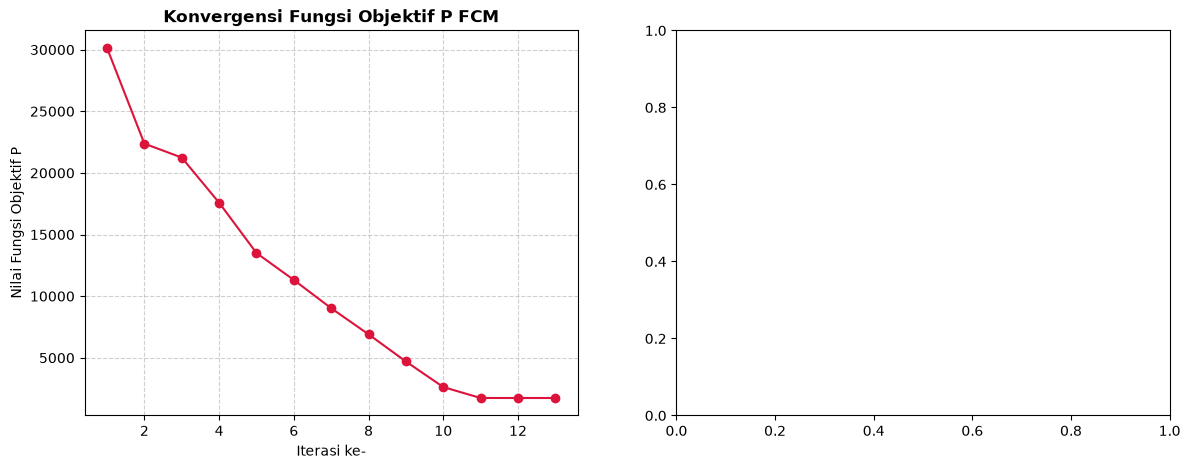

In [24]:
# ==============================================================================
# 8. VISUALISASI HASIL PELATIHAN & EVALUASI
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Konvergensi Nilai Fungsi Objektif P FCM
if hasattr(fcm_model, 'objective_history_') and len(fcm_model.objective_history_) > 0:
    axes[0].plot(range(1, len(fcm_model.objective_history_) + 1), fcm_model.objective_history_, marker='o', color='crimson')
    axes[0].set_title('Konvergensi Fungsi Objektif P FCM', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Iterasi ke-')
    axes[0].set_ylabel('Nilai Fungsi Objektif P')
    axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Scatter Plot PC1 vs PC2
# Ambil label kluster dominan dari fcm_model.labels_ atau argmax mu_train
cluster_labels = getattr(fcm_model, 'labels_', None)
if cluster_labels is None and 'mu_train' in results.get('data', {}):
    cluster_labels = np.argmax(results['data']['mu_train'], axis=1)
elif cluster_labels is None:
    cluster_labels = np.zeros(len(X_pca_train), dtype=int)

scatter = axes[1].scatter(X_pca_train[:, 0], X_pca_train[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6, edgecolors='k')
centers_pca = fcm_model.centers_
axes[1].scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=200, edgecolors='black', label='Pusat FCM (V)')
axes[1].set_title('Proyeksi Data Latih pada PC1 vs PC2', fontsize=12, fontweight='bold')
pc1_ratio = pca.explained_variance_ratio_[0]*100 if hasattr(pca, 'explained_variance_ratio_') and len(pca.explained_variance_ratio_) > 0 else 0
pc2_ratio = pca.explained_variance_ratio_[1]*100 if hasattr(pca, 'explained_variance_ratio_') and len(pca.explained_variance_ratio_) > 1 else 0
axes[1].set_xlabel(f'PC1 ({pc1_ratio:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pc2_ratio:.1f}%)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Tampilkan Confusion Matrix jika tersedia
knn_metrics = results.get('metrics', {}).get('knn_test', {})
if 'confusion_matrix' in knn_metrics:
    cm = np.array(knn_metrics['confusion_matrix'])
    labels = knn_metrics.get('labels', results.get('class_names', class_names))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    plt.title('Confusion Matrix pada Data Uji (Test Set)', fontweight='bold')
    plt.show()


---
## 9. Evaluasi 4 Skenario Pengujian Sistem
Sesuai Dokumen Konteks Sistem, pipeline mengevaluasi 4 konfigurasi model:
1. **Skenario 1a:** MobileNetV3-Small + PCA + (FCM + KNN) $\rightarrow$ Model Usulan Utama
2. **Skenario 1b:** MobileNetV3-Small + PCA + KNN
3. **Skenario 2a:** (Histogram HSV + GLCM) + PCA + (FCM + KNN)
4. **Skenario 2b:** (Histogram HSV + GLCM) + PCA + KNN


In [ ]:
# ==============================================================================
# 9. EVALUASI 4 SKENARIO PENGUJIAN LENGKAP
# ==============================================================================
print('=' * 75)
print('             TABEL PERBANDINGAN 4 SKENARIO PENGUJIAN')
print('=' * 75)
import pandas as pd
scenarios_res = results.get('metrics', {}).get('scenarios', {})
if not scenarios_res:
    scenarios_res = run_four_scenarios(
        X_train_raw=results['data']['X_train_pca'],
        y_train=results['data']['y_train'],
        X_test_raw=results['data']['X_test_pca'],
        y_test=results['data']['y_test'],
        config=config,
        class_names=results.get('class_names', class_names),
    )
records = []
for code, sc in scenarios_res.items():
    if isinstance(sc, dict) and 'metrics' in sc:
        m = sc['metrics']
        records.append({
            'Skenario': code,
            'Nama': sc.get('name', code),
            'Akurasi': f"{m.get('accuracy', 0):.2%}",
            'F1-Macro': f"{m.get('f1_macro', 0):.4f}",
            'Presisi-Macro': f"{m.get('precision_macro', 0):.4f}",
            'Recall-Macro': f"{m.get('recall_macro', 0):.4f}",
        })
df_scenarios = pd.DataFrame(records)
print(df_scenarios.to_string(index=False))


---
## 10. Penyimpanan Artefak Model ke Direktori `models/`
Menyimpan 5 artefak model:
1. `scaler.pkl`: StandardScaler
2. `pca.pkl`: Model reduksi dimensi PCA
3. `fcm_centers.npy`: Koordinat pusat cluster FCM di ruang PCA
4. `knn.pkl`: Model klasifikasi KNN terlatih pada $[\mathbf{X}_{PCA} \parallel \alpha \cdot \boldsymbol{\mu}]$
5. `meta.json`: Metadata konfigurasi, nama kelas dinamis, versi library, bobot $\alpha$, dan ringkasan metrik 4 skenario.

File-file ini akan dimuat oleh aplikasi Streamlit (`app.py`) untuk inferensi langsung tanpa perlu melatih ulang.


In [ ]:
# ==============================================================================
# 10. SIMPAN ARTEFAK & VERIFIKASI PEMUATAN KEMBALI
# ==============================================================================
MODELS_DIR = os.path.join(REPO_ROOT, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

# Simpan artefak resmi ke folder models/
saved_files = save_models(
    models_dir=MODELS_DIR,
    scaler=scaler,
    pca=pca,
    fcm_centers=fcm_model.centers_,
    knn=knn,
    config=config,
    class_names=results.get('class_names', class_names),
    feature_extractor=config.get('features', {}).get('feature_extractor', 'mobilenetv3_small'),
    alpha=config.get('knn', {}).get('alpha', 1.0),
    meta={
        'metrics': metrics,
        'scenarios': scenarios_res if 'scenarios_res' in locals() else {},
    }
)

print(f"[+] Artefak berhasil disimpan di: {MODELS_DIR}")
print(f"[+] File tersimpan: {list(saved_files.keys())}")

# Verifikasi pemuatan kembali via load_models()
print("\n[*] Memverifikasi pemanggilan load_models()...")
loaded = load_models(models_dir=MODELS_DIR)
if loaded is not None:
    print("[SUCCESS] Seluruh 5 artefak model berhasil dimuat kembali secara valid!")
    print(f"          - Scaler     : {type(loaded['scaler']).__name__}")
    print(f"          - PCA        : {type(loaded['pca']).__name__}")
    print(f"          - FCM Centers: shape {loaded['fcm_centers'].shape}")
    print(f"          - KNN        : {type(loaded['knn']).__name__}")
    print(f"          - Meta Keys  : {list(loaded.get('meta', {}).keys())}")
else:
    print("[ERROR] Gagal memuat artefak dari models/")

# Jika berjalan di Colab tanpa Drive Mount permanen, download zip models/ ke laptop lokal:
if IN_COLAB:
    import shutil
    from google.colab import files
    print("\n[*] Menyiapkan arsip ZIP models untuk diunduh langsung ke komputer lokal...")
    zip_path = shutil.make_archive('/content/models', 'zip', MODELS_DIR)
    print(f"[+] Mengunduh {zip_path}...")
    files.download(zip_path)


In [ ]:
# ==============================================================================
# 11. COMMIT & PUSH ARTEFAK MODELS KHUSUS KE BRANCH 'colab'
# ==============================================================================
# Masukkan Personal Access Token (PAT) GitHub Anda jika ingin langsung push dari Colab:
# Buat token di: https://github.com/settings/tokens (pilih scope: repo)

GITHUB_USERNAME = 'Leoudah'   # Username GitHub pemilik repo tujuan
GITHUB_TOKEN = ''             # Tempel Personal Access Token (PAT) di sini
REPO_NAME = 'Garbage-Classification-FCM'
BRANCH_NAME = 'colab'         # Branch khusus artefak model

if GITHUB_TOKEN:
    !git config user.name 'Colab Trainer'
    !git config user.email 'colab@google.com'
    
    # Buat branch 'colab' yang terisolasi dan bersih khusus folder models/
    !git checkout -B {BRANCH_NAME}
    !git add -f models/scaler.pkl models/pca.pkl models/fcm_centers.npy models/knn.pkl models/meta.json
    !git commit -m 'feat(models): artefak model resmi hasil training Colab'
    remote_target = f'https://{GITHUB_USERNAME}:{GITHUB_TOKEN}@' + f'github.com/{GITHUB_USERNAME}/{REPO_NAME}.git'
    !git push -f -u {remote_target} {BRANCH_NAME}
    print(f'[SUCCESS] Artefak model resmi berhasil di-push secara bersih ke branch {BRANCH_NAME}!')
else:
    print('[INFO] Masukkan GITHUB_TOKEN di sel ini jika ingin langsung push ke branch colab,')
    print('       atau unduh file models.zip yang otomatis diunduh di sel sebelumnya.')
